Note: you may need to restart the kernel to use updated packages.
Starting simulation...
t=   0  1 firm enters at x=0.40, p=1.33 -> total 3
t=   5  1 firm enters at x=0.65, p=1.50 -> total 4
t=  10  1 firm enters at x=0.40, p=1.17 -> total 5
t=  15  1 firm enters at x=0.40, p=1.17 -> total 6
t=  20  1 firm enters at x=0.60, p=1.33 -> total 7
t=  22  1 firm(s) exit -> 6 remaining
t=  25  1 firm enters at x=0.65, p=1.33 -> total 7
t=  28  1 firm(s) exit -> 6 remaining
t=  30  1 firm enters at x=0.70, p=1.33 -> total 7
t=  35  1 firm enters at x=0.75, p=1.33 -> total 8
t=  38  1 firm(s) exit -> 7 remaining
t=  40  1 firm(s) exit -> 6 remaining
t=  40  1 firm enters at x=0.80, p=1.33 -> total 7
t=  45  1 firm(s) exit -> 6 remaining
t=  45  1 firm enters at x=0.85, p=1.33 -> total 7

--- Final State ---
Active firms: 7
  firm 0: x=0.720  p=1.520  q=0.000  profit=-0.0400  buffer=0.301
  firm 1: x=0.410  p=1.293  q=0.000  profit=-0.0400  buffer=0.080
  firm 2: x=0.410  p=1.027  q=0.416  profi

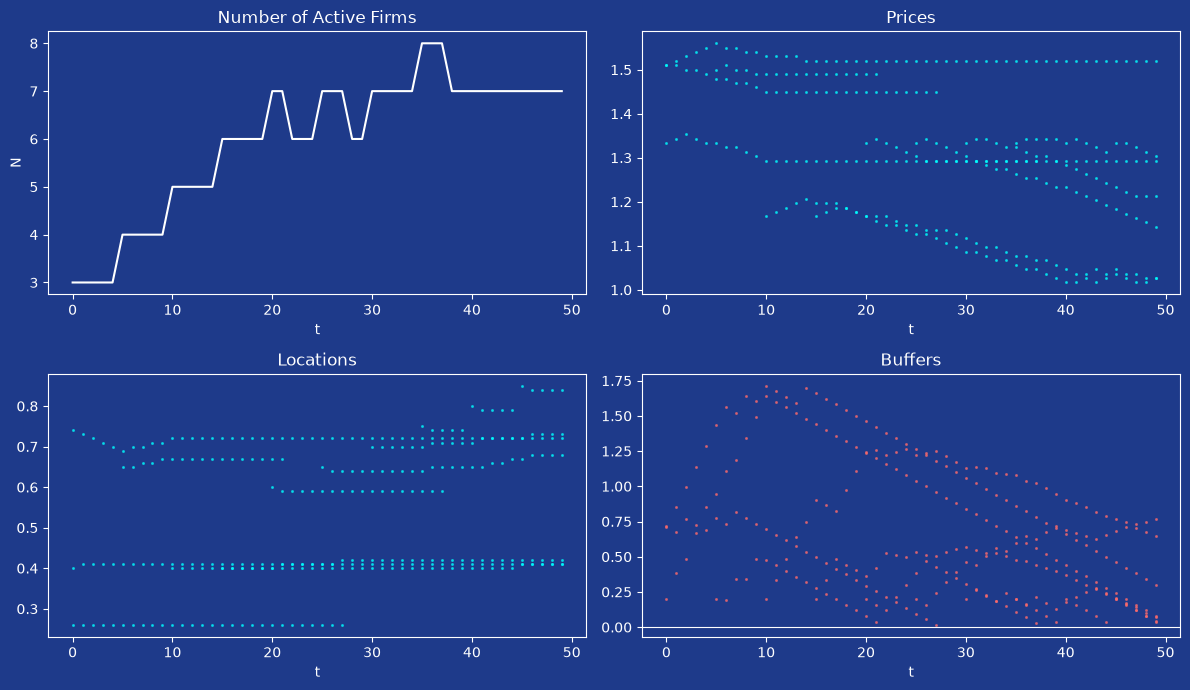

In [ ]:
%pip install matplotlib numpy
import matplotlib.pyplot as plt
import numpy as np

# PARAMETERS

L = 1.0  # market length 
N_CONS = 401  # number of consumers on the grid
V = 10.0  # consumer reservation value
t = 1.0  # transport cost per unit distance

c0 = 1.0  # marginal cost
cF = 0.04  # fixed cost per period

dp = 0.01  # price adjustment step
dx = 0.01  # location adjustment step
p_max = V  # maximum admissible price

B0 = 0.50  # initial buffer of a firm
ENTRY_COST = 0.30  # sunk entry cost
ENTRY_EVERY = 5  # entry frequency
MAX_FIRMS = 8  # cap on simultaneous firms
ENTRY_MARGIN = 0.0  # minimum expected profit to enter

T = 600  # simulation periods
SEED = 42

rng = np.random.default_rng(SEED)

# Consumer grid (total mass = 1)
z = np.linspace(0.0, L, N_CONS)
mass = 1.0 / N_CONS

# DEMAND AND PROFITS (N firms)

def calculate_profit(x, p):
    x = np.asarray(x, dtype=float)
    p = np.asarray(p, dtype=float)
    n = len(x)

    if n == 0:
        return np.array([]), np.array([])

    full_price = p[:, None] + t * np.abs(x[:, None] - z[None, :])
    winner = np.argmin(full_price, axis=0)
    best_full = full_price[winner, np.arange(N_CONS)]
    served = (V - best_full) >= 0

    q = np.zeros(n)
    for i in range(n):
        q[i] = np.sum((winner == i) & served) * mass

    profits = (p - c0) * q - cF
    return profits, q



# BEST RESPONSE IN PRICE AND LOCATION

def best_price(x, p, firm):
    current_price = p[firm]
    best_p = current_price
    best_profit = calculate_profit(x, p)[0][firm]

    for new_price in [current_price - dp, current_price + dp]:
        if 0 <= new_price <= p_max:
            p_test = p.copy()
            p_test[firm] = new_price
            new_profit = calculate_profit(x, p_test)[0][firm]

            if new_profit > best_profit:
                best_profit = new_profit
                best_p = new_price

    return best_p


def best_location(x, p, firm):
    current_x = x[firm]
    best_x = current_x
    best_profit = calculate_profit(x, p)[0][firm]

    for new_x in [current_x - dx, current_x + dx]:
        if 0 <= new_x <= L:
            x_test = x.copy()
            x_test[firm] = new_x
            new_profit = calculate_profit(x_test, p)[0][firm]

            if new_profit > best_profit:
                best_profit = new_profit
                best_x = new_x

    return best_x

# FIRM ENTRY AND EXIT

def update_buffers(buffer, profits):
    return buffer + profits


def exit_firms(x, p, buffer):
    alive = buffer >= 0.0
    return x[alive], p[alive], buffer[alive], np.where(~alive)[0]


def evaluate_entry(x, p, n_x=21, n_p=25):
    x_grid = np.linspace(0.0, L, n_x)
    p_grid = np.linspace(c0, p_max * 0.5, n_p)
    best = (None, None, -np.inf)

    for xe in x_grid:
        for pe in p_grid:
            x_test = np.append(x, xe)
            p_test = np.append(p, pe)
            pi_e = calculate_profit(x_test, p_test)[0][-1]

            if pi_e > best[2]:
                best = (xe, pe, pi_e)

    return best


def try_entry(x, p, buffer):
    if len(x) >= MAX_FIRMS:
        return x, p, buffer, False

    xe, pe, pi_e = evaluate_entry(x, p)

    if pi_e > ENTRY_MARGIN:
        x = np.append(x, xe)
        p = np.append(p, pe)
        buffer = np.append(buffer, B0 - ENTRY_COST)
        return x, p, buffer, True

    return x, p, buffer, False

# SIMULATION

def simulate(n_firms_0=2, T=T, adjust_location=True, verbose=True):
    x = np.linspace(0.25 * L, 0.75 * L, n_firms_0)
    p = np.full(n_firms_0, c0 + 0.5)
    buffer = np.full(n_firms_0, B0)

    hist = {
        "n_firms": [],
        "prices": [],
        "locations": [],
        "profits": [],
        "buffers": [],
        "entries": [],
        "exits": [],
    }

    for step in range(T):
        for i in rng.permutation(len(x)):
            p[i] = best_price(x, p, i)
            if adjust_location:
                x[i] = best_location(x, p, i)

        profits, q = calculate_profit(x, p)
        buffer = update_buffers(buffer, profits)

        x, p, buffer, gone = exit_firms(x, p, buffer)
        if verbose and len(gone) > 0:
            print(f"t={step:4d}  {len(gone)} firm(s) exit -> {len(x)} remaining")

        entered = False
        if step % ENTRY_EVERY == 0:
            x, p, buffer, entered = try_entry(x, p, buffer)
            if verbose and entered:
                print(
                    f"t={step:4d}  1 firm enters at x={x[-1]:.2f}, "
                    f"p={p[-1]:.2f} -> total {len(x)}"
                )

        hist["n_firms"].append(len(x))
        hist["prices"].append(p.copy())
        hist["locations"].append(x.copy())
        hist["profits"].append(calculate_profit(x, p)[0].copy())
        hist["buffers"].append(buffer.copy())
        hist["entries"].append(entered)
        hist["exits"].append(len(gone))

        if len(x) == 0:
            if verbose:
                print(f"t={step}: empty market, end of simulation.")
            break

    return x, p, buffer, hist

# PLOTS

def plot_results(hist):
    T_eff = len(hist["n_firms"])
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))

    
    fig.patch.set_facecolor("#1E3A8A")
    for a in ax.flat:
        a.set_facecolor("#1E3A8A")
        a.title.set_color("white")
        a.xaxis.label.set_color("white")
        a.yaxis.label.set_color("white")
        a.tick_params(colors="white")
        for spine in a.spines.values():
            spine.set_color("white")

    
    ax[0, 0].plot(hist["n_firms"], lw=1.5, color="white")
    ax[0, 0].set_title("Number of Active Firms")
    ax[0, 0].set_xlabel("t")
    ax[0, 0].set_ylabel("N")

    
    for k, key, title in [
        (1, "prices", "Prices"),
        (2, "locations", "Locations"),
    ]:
        a = ax[0, 1] if k == 1 else ax[1, 0]
        for step in range(T_eff):
            vals = hist[key][step]
            a.scatter([step] * len(vals), vals, s=1.5, alpha=0.6, color="cyan")
        a.set_title(title)
        a.set_xlabel("t")

    
    for step in range(T_eff):
        vals = hist["buffers"][step]
        # Punts en blanc
        ax[1, 1].scatter([step] * len(vals), vals, s=1.5, alpha=0.6, color="white")
    
    ax[1, 1].axhline(0, color="white", lw=0.8)
    
    
    ax[1, 1].set_title("Buffers", color="white")
    ax[1, 1].set_xlabel("t", color="white")
    ax[1, 1].tick_params(colors="white")
    for spine in ax[1, 1].spines.values():
        spine.set_color("white")

    plt.tight_layout()
    plt.show(block=True)


if __name__ == "__main__":
    print("Starting simulation...")
    x, p, buffer, hist = simulate(n_firms_0=2, T=50)

    print("\n--- Final State ---")
    print("Active firms:", len(x))

    pi, q = calculate_profit(x, p)
    for i in range(len(x)):
        print(
            f"  firm {i}: x={x[i]:.3f}  p={p[i]:.3f}  "
            f"q={q[i]:.3f}  profit={pi[i]:+.4f}  buffer={buffer[i]:.3f}"
        )

    print("\nOpening results plot...")
    plot_results(hist)